In [17]:
import os
import warnings
import gc
import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow.keras import layers, models
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.metrics import (f1_score, precision_score, recall_score,
                             accuracy_score, roc_auc_score,
                             average_precision_score,
                             balanced_accuracy_score, confusion_matrix)
from scipy import stats
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings('ignore')
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'
os.environ['TF_FORCE_GPU_ALLOW_GROWTH'] = 'true'
os.environ['OMP_NUM_THREADS'] = '2'
os.environ['TF_NUM_INTRAOP_THREADS'] = '2'
os.environ['TF_NUM_INTEROP_THREADS'] = '1'
CONFIG = {
    'seeds': [42, 123],              # Reduced from 5 to 2
    'num_clients': 20,
    'num_rounds': 8,                 # Reduced from 15 to 8
    'local_epochs': 3,               # Reduced from 5 to 3
    'batch_size': 128,               # Increased to reduce steps
    'malicious_ratio': 0.20,
    'dropout_rate': 0.10,
    'straggler_rate': 0.30,
    'poison_rate': 0.30,
    'weight_scale_lambda': 3.0,
    'val_percentile': 5,
    'beta_trust': 0.9,
}

os.makedirs('results', exist_ok=True)
os.makedirs('results/tables', exist_ok=True)
os.makedirs('results/figures', exist_ok=True)

print("Configuration set (lightweight mode for local execution).")
print(f"Seeds: {CONFIG['seeds']}")
print(f"Rounds: {CONFIG['num_rounds']}")
print(f"Total FL runs in Exp 2: {2 * 5 * 4} = 40 (was 100)")

Configuration set (lightweight mode for local execution).
Seeds: [42, 123]
Rounds: 8
Total FL runs in Exp 2: 40 = 40 (was 100)


In [18]:
import urllib.request

url = "https://zenodo.org/records/15336998/files/UAVIDS-2025.csv"
output_path = "UAVIDS-2025.csv"

print("Downloading UAVIDS-2025 from Zenodo...")
try:
    urllib.request.urlretrieve(url, output_path)
    print(f"Downloaded: {output_path}")
except Exception as e:
    print(f"Zenodo download failed: {e}")
    print("Trying alternate URL...")
    url_alt = "https://zenodo.org/record/15336998/files/UAVIDS-2025.csv"
    urllib.request.urlretrieve(url_alt, output_path)
    print(f"Downloaded: {output_path}")

if os.path.exists(output_path):
    df_check = pd.read_csv(output_path, nrows=5)
    print(f"\nFile loaded. Columns: {list(df_check.columns)}")
    print(f"Shape (first 5 rows): {df_check.shape}")

Downloaded: UAVIDS-2025.csv

File loaded. Columns: ['FlowID', 'FlowDuration/s', 'SrcAddr', 'SrcPort', 'DstAddr', 'DstPort', 'Protocol', 'TxPackets', 'RxPackets', 'LostPackets', 'TxBytes', 'RxBytes', 'TxPacketRate/s', 'RxPacketRate/s', 'TxByteRate/s', 'RxByteRate/s', 'MeanDelay/s', 'MeanJitter/s', 'Throughput/Kbps', 'MeanPacketSize', 'PacketDropRate', 'AverageHopCount', 'label']
Shape (first 5 rows): (5, 23)


In [21]:
df = pd.read_csv(output_path)

print("=" * 70)
print("DATASET OVERVIEW")
print("=" * 70)
print(f"Shape: {df.shape}")
print(f"\nColumns ({len(df.columns)}):")
for i, col in enumerate(df.columns):
    print(f"  {i+1:2d}. {col}")
print(f"\nData types:\n{df.dtypes.value_counts()}")
print(f"\nFirst 5 rows:")
print(df.head())
print(f"\nMissing values:\n{df.isnull().sum().sum()} total")

label_col = 'Label' if 'Label' in df.columns else df.columns[-1]
print(f"\nClass distribution:")
print(df[label_col].value_counts())

DATASET OVERVIEW
Shape: (122171, 23)

Columns (23):
   1. FlowID
   2. FlowDuration/s
   3. SrcAddr
   4. SrcPort
   5. DstAddr
   6. DstPort
   7. Protocol
   8. TxPackets
   9. RxPackets
  10. LostPackets
  11. TxBytes
  12. RxBytes
  13. TxPacketRate/s
  14. RxPacketRate/s
  15. TxByteRate/s
  16. RxByteRate/s
  17. MeanDelay/s
  18. MeanJitter/s
  19. Throughput/Kbps
  20. MeanPacketSize
  21. PacketDropRate
  22. AverageHopCount
  23. label

Data types:
float64    10
int64       9
str         4
Name: count, dtype: int64

First 5 rows:
   FlowID  FlowDuration/s        SrcAddr  SrcPort       DstAddr  DstPort  \
0       1         175.007  192.168.0.150        9  192.168.0.16        9   
1       2         175.008  192.168.0.150        9  192.168.0.19        9   
2       3         175.010  192.168.0.150        9  192.168.0.24        9   
3       4         175.014  192.168.0.150        9  192.168.0.34        9   
4       5         175.017  192.168.0.150        9  192.168.0.39        9  

In [22]:
# ============================================================
# PREPROCESSING 
# ============================================================
print("=" * 70)
print("PREPROCESSING")
print("=" * 70)

# ---- Step 1: Identify the label column ----
label_candidates = ['Label', 'label', 'Class', 'class', 'Attack',
                    'attack_type', 'Attack Type', 'attack']
label_col = None
for c in label_candidates:
    if c in df.columns:
        label_col = c
        break
if label_col is None:
    label_col = df.columns[-1]

print(f"Label column identified: '{label_col}'")

# ---- Step 2: Convert labels to plain Python strings ----
# The column is a pandas StringArray; convert via .astype(str) then tolist()
y_raw = df[label_col].astype(str).tolist()
print(f"Unique raw labels: {sorted(set(y_raw))}")

# ---- Step 3: Explicit mapping of UAVIDS-2025 classes ----
NORMAL_LABEL = 'Normal Traffic'
y_binary = np.array([0 if lbl == NORMAL_LABEL else 1 for lbl in y_raw],
                    dtype=int)

print(f"\nNormal label used: '{NORMAL_LABEL}'")
print(f"Binary distribution:")
print(f"  Normal (0): {(y_binary == 0).sum()}")
print(f"  Attack (1): {(y_binary == 1).sum()}")

if (y_binary == 0).sum() == 0:
    raise ValueError(
        f"No normal samples found. Check that the label column contains "
        f"'{NORMAL_LABEL}'. Current unique values: {sorted(set(y_raw))}"
    )

# ---- Step 4: Multiclass labels for reference (not used in modelling) ----
classes_sorted = sorted(set(y_raw))
class_to_idx = {c: i for i, c in enumerate(classes_sorted)}
y_multi = np.array([class_to_idx[lbl] for lbl in y_raw], dtype=int)
print(f"\nMulticlass encoding: {class_to_idx}")

# ---- Step 5: Keep only numeric features ----
X = df.drop(columns=[label_col])
X_numeric = X.select_dtypes(include=[np.number])
print(f"\nNumeric features detected: {X_numeric.shape[1]}")

if X_numeric.shape[1] < 3:
    raise ValueError(f"Only {X_numeric.shape[1]} numeric features found. "
                     f"Expected ≥19. Check dataset integrity.")

# ---- Step 6: Handle inf / NaN ----
X_numeric = X_numeric.replace([np.inf, -np.inf], np.nan)
X_numeric = X_numeric.fillna(X_numeric.median())

# ---- Step 7: Standardize ----
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_numeric)
input_dim = X_scaled.shape[1]
print(f"Final feature dimension: {input_dim}")

# ---- Step 8: Train / test split (stratified on binary) ----
X_train, X_test, y_train_bin, y_test_bin, y_train_multi, y_test_multi = \
    train_test_split(
        X_scaled, y_binary, y_multi,
        test_size=0.2, random_state=42, stratify=y_binary)

print(f"\nTrain: {X_train.shape}, Test: {X_test.shape}")
print(f"Train label distribution: {np.bincount(y_train_bin)}")
print(f"Test  label distribution: {np.bincount(y_test_bin)}")

# ---- Step 9: Held-out normal validation set for one-class thresholding ----
normal_idx = np.where(y_train_bin == 0)[0]
val_size = min(5000, len(normal_idx))
np.random.seed(42)
val_idx = np.random.choice(normal_idx, val_size, replace=False)
X_val_normal = X_train[val_idx]

X_train_all = X_train
y_train_all = y_train_bin

print(f"\nValidation normal set: {X_val_normal.shape}")
print(f"Supervised training set: {X_train_all.shape}")

# ---- Step 10: Diagnostic summary ----
print("\n" + "=" * 70)
print("PREPROCESSING SUMMARY")
print("=" * 70)
print(f"  Total samples:           {len(y_binary)}")
print(f"  Normal samples:          {(y_binary == 0).sum()}")
print(f"  Attack samples:          {(y_binary == 1).sum()}")
print(f"  Class imbalance ratio:   1 : {(y_binary == 1).sum() / max(1,(y_binary==0).sum()):.2f}")
print(f"  Feature dimension:       {input_dim}")
print(f"  Training samples:        {len(X_train)}")
print(f"  Test samples:            {len(X_test)}")
print(f"  Validation normal samples: {len(X_val_normal)}")

PREPROCESSING
Label column identified: 'label'
Unique raw labels: ['Blackhole Attack', 'Flooding Attack', 'Normal Traffic', 'Sybil Attack', 'Wormhole Attack']

Normal label used: 'Normal Traffic'
Binary distribution:
  Normal (0): 26172
  Attack (1): 95999

Multiclass encoding: {'Blackhole Attack': 0, 'Flooding Attack': 1, 'Normal Traffic': 2, 'Sybil Attack': 3, 'Wormhole Attack': 4}

Numeric features detected: 19
Final feature dimension: 19

Train: (97736, 19), Test: (24435, 19)
Train label distribution: [20937 76799]
Test  label distribution: [ 5235 19200]

Validation normal set: (5000, 19)
Supervised training set: (97736, 19)

PREPROCESSING SUMMARY
  Total samples:           122171
  Normal samples:          26172
  Attack samples:          95999
  Class imbalance ratio:   1 : 3.67
  Feature dimension:       19
  Training samples:        97736
  Test samples:            24435
  Validation normal samples: 5000


In [23]:
def focal_loss(gamma=2., alpha=0.25):
    def focal_loss_fixed(y_true, y_pred):
        epsilon = tf.keras.backend.epsilon()
        y_pred = tf.clip_by_value(y_pred, epsilon, 1. - epsilon)
        cross_entropy = -y_true * tf.math.log(y_pred)
        loss = alpha * tf.math.pow(1 - y_pred, gamma) * cross_entropy
        return tf.reduce_mean(loss)
    return focal_loss_fixed


def build_mlp(input_dim):
    return models.Sequential([
        layers.Input(shape=(input_dim,)),
        layers.Dense(64, activation='relu'),
        layers.Dropout(0.3),
        layers.Dense(32, activation='relu'),
        layers.Dropout(0.3),
        layers.Dense(1, activation='sigmoid')])


def build_1d_cnn(input_dim):
    return models.Sequential([
        layers.Input(shape=(input_dim,)),
        layers.Reshape((input_dim, 1)),
        layers.Conv1D(32, 3, activation='relu', padding='same'),
        layers.MaxPooling1D(2),
        layers.Conv1D(16, 3, activation='relu', padding='same'),
        layers.GlobalAveragePooling1D(),
        layers.Dense(16, activation='relu'),
        layers.Dropout(0.3),
        layers.Dense(1, activation='sigmoid')])


def build_gru(input_dim):
    return models.Sequential([
        layers.Input(shape=(input_dim,)),
        layers.Reshape((input_dim, 1)),
        layers.GRU(32),
        layers.Dropout(0.3),
        layers.Dense(16, activation='relu'),
        layers.Dense(1, activation='sigmoid')])


def build_autoencoder(input_dim):
    """Autoencoder for one-class anomaly detection.
    Bottleneck is min(8, input_dim // 2) so the encoder never collapses
    to a scalar when input_dim is small."""
    bottleneck = max(4, min(8, input_dim // 2))

    inputs = layers.Input(shape=(input_dim,), name='ae_input')
    x = layers.Dense(max(16, input_dim * 2), activation='relu')(inputs)
    x = layers.Dense(bottleneck, activation='relu', name='bottleneck')(x)
    x = layers.Dense(max(16, input_dim * 2), activation='relu')(x)
    outputs = layers.Dense(input_dim, activation='linear',
                           name='reconstruction')(x)

    model = models.Model(inputs, outputs)
    return model

MODEL_BUILDERS = {
    'MLP': build_mlp,
    '1D-CNN': build_1d_cnn,
    'GRU': build_gru,
    'Autoencoder': build_autoencoder,
}

print("Models defined:", list(MODEL_BUILDERS.keys()))

Models defined: ['MLP', '1D-CNN', 'GRU', 'Autoencoder']


In [24]:
def select_threshold(model, X_val_normal, percentile=5):
    scores = model.predict(X_val_normal, verbose=0).flatten()
    return float(np.percentile(scores, percentile))


def evaluate_binary(model, X_test, y_test, tau=0.5):
    scores = model.predict(X_test, verbose=0).flatten()
    y_pred = (scores >= tau).astype(int)

    tp = int(np.sum((y_pred == 1) & (y_test == 1)))
    fp = int(np.sum((y_pred == 1) & (y_test == 0)))
    fn = int(np.sum((y_pred == 0) & (y_test == 1)))
    tn = int(np.sum((y_pred == 0) & (y_test == 0)))

    prec = tp / max(1, tp + fp)
    rec = tp / max(1, tp + fn)
    f1 = 2 * prec * rec / max(1e-9, prec + rec)
    fpr = fp / max(1, fp + tn)
    acc = (tp + tn) / max(1, tp + tn + fp + fn)
    try:
        bal_acc = balanced_accuracy_score(y_test, y_pred)
    except Exception:
        bal_acc = 0.0
    try:
        auc = roc_auc_score(y_test, scores)
        pr_auc = average_precision_score(y_test, scores)
    except ValueError:
        auc, pr_auc = 0.0, 0.0

    return {
        'F1': f1, 'Precision': prec, 'Recall': rec, 'FPR': fpr,
        'Accuracy': acc, 'Balanced_Accuracy': bal_acc,
        'AUC': auc, 'PR_AUC': pr_auc,
        'TP': tp, 'FP': fp, 'FN': fn, 'TN': tn,
    }


print("Evaluation functions defined.")

Evaluation functions defined.


In [25]:
def partition_clients(X, y, num_clients=CONFIG['num_clients'], seed=42):
    np.random.seed(seed)
    sorted_idx = np.argsort(y)
    chunks = np.array_split(sorted_idx, num_clients)
    client_X = [X[c] for c in chunks]
    client_y = [y[c] for c in chunks]
    return client_X, client_y


def simulate_client_availability(num_clients, dropout_rate, straggler_rate, seed):
    np.random.seed(seed)
    active = np.random.rand(num_clients) > dropout_rate
    stragglers = np.random.rand(num_clients) < straggler_rate
    return active, stragglers


def average_weights(weights_list):
    return [np.mean(layer, axis=0) for layer in zip(*weights_list)]


def feddwm_aggregation(weights_list, sizes, trust):
    w_sum = np.sum(np.array(sizes) * np.array(trust)) + 1e-12
    out = []
    for layer in zip(*weights_list):
        num = np.sum([w * (s * r) / w_sum
                      for w, s, r in zip(layer, sizes, trust)], axis=0)
        out.append(num)
    return out


def update_trust_weights(trust, local_weights, global_weights, beta=CONFIG['beta_trust']):
    g_vec = np.concatenate([w.flatten() for w in global_weights])
    for k, wl in enumerate(local_weights):
        c_vec = np.concatenate([w.flatten() for w in wl])
        denom = (np.linalg.norm(c_vec) * np.linalg.norm(g_vec)) + 1e-12
        sim = float(np.dot(c_vec, g_vec) / denom)
        sim = max(0.0, sim)
        trust[k] = beta * trust[k] + (1 - beta) * sim
    return trust


def krum_aggregation(weights_list, num_malicious, multi=False):
    K = len(weights_list)
    m = max(1, K - num_malicious - 2) if multi else 1
    flat = np.array([np.concatenate([w.flatten() for w in wl])
                     for wl in weights_list])
    dist = np.zeros((K, K))
    for i in range(K):
        for j in range(K):
            dist[i, j] = np.linalg.norm(flat[i] - flat[j])
    n_neigh = max(1, K - num_malicious - 2)
    scores = np.array([np.sum(np.sort(dist[i])[:n_neigh + 1]) for i in range(K)])
    selected = np.argsort(scores)[:m]
    return average_weights([weights_list[i] for i in selected])


def trimmed_mean_aggregation(weights_list, trim_ratio=0.1):
    K = len(weights_list)
    n_trim = max(1, int(K * trim_ratio))
    out = []
    for layer_idx in range(len(weights_list[0])):
        stacked = np.stack([wl[layer_idx] for wl in weights_list], axis=0)
        sorted_v = np.sort(stacked, axis=0)
        trimmed = sorted_v[n_trim:K - n_trim]
        out.append(np.mean(trimmed, axis=0))
    return out


def median_aggregation(weights_list):
    out = []
    for layer_idx in range(len(weights_list[0])):
        stacked = np.stack([wl[layer_idx] for wl in weights_list], axis=0)
        out.append(np.median(stacked, axis=0))
    return out


def aggregate(weights_list, sizes, trust, method, num_malicious):
    if method == 'fedaverage':
        return average_weights(weights_list)
    if method == 'feddwm':
        return feddwm_aggregation(weights_list, sizes, trust)
    if method == 'krum':
        return krum_aggregation(weights_list, num_malicious, multi=False)
    if method == 'multikrum':
        return krum_aggregation(weights_list, num_malicious, multi=True)
    if method == 'trimmed_mean':
        return trimmed_mean_aggregation(weights_list, trim_ratio=0.1)
    if method == 'median':
        return median_aggregation(weights_list)
    raise ValueError(f"Unknown aggregation: {method}")

print("FL aggregation methods defined.")

FL aggregation methods defined.


In [26]:
# ============================================================
# POISONING ATTACKS
# ============================================================
def poison_data_local(X_local, y_local, poison_rate=CONFIG['poison_rate']):
    y_poisoned = y_local.copy().astype(int)
    n = int(len(y_poisoned) * poison_rate)
    if n > 0:
        idx = np.random.choice(len(y_poisoned), n, replace=False)
        y_poisoned[idx] = 1 - y_poisoned[idx]
    return X_local, y_poisoned


def poison_model_weights(local_weights, scale_factor=CONFIG['weight_scale_lambda'],
                        noise_std=0.1):
    return [w * scale_factor + np.random.normal(0, noise_std, w.shape)
            for w in local_weights]


def backdoor_data_poisoning(X_local, y_local, trigger_pattern, target_label=0):
    X_poisoned = np.array(X_local, dtype=np.float32, copy=True)
    y_poisoned = np.array(y_local, dtype=int, copy=True)

    n_samples, n_features = X_poisoned.shape
    n_poison = int(0.10 * n_samples)
    if n_poison <= 0:
        return X_poisoned, y_poisoned

    # Ensure the trigger is a full-length vector matching the feature dimension
    trigger = np.asarray(trigger_pattern, dtype=np.float32).flatten()
    if trigger.size != n_features:
        trigger = np.resize(trigger, n_features)

    # Select samples and inject trigger into every feature of those samples
    idx = np.random.choice(n_samples, n_poison, replace=False)
    X_poisoned[idx, :] = X_poisoned[idx, :] + trigger[np.newaxis, :]
    y_poisoned[idx] = target_label

    return X_poisoned, y_poisoned

print("Poisoning attacks defined (backdoor fixed).")

Poisoning attacks defined (backdoor fixed).


In [27]:
def federated_training(model_builder, X_train, y_train, X_val_normal,
                       X_test, y_test,
                       num_clients=CONFIG['num_clients'],
                       malicious_ratio=CONFIG['malicious_ratio'],
                       attack_type=None,
                       poison_rate=CONFIG['poison_rate'],
                       weight_scale_lambda=CONFIG['weight_scale_lambda'],
                       num_rounds=CONFIG['num_rounds'],
                       local_epochs=CONFIG['local_epochs'],
                       aggregation='feddwm',
                       dropout_rate=CONFIG['dropout_rate'],
                       straggler_rate=CONFIG['straggler_rate'],
                       seed=42):

    # ---- MEMORY MANAGEMENT ----
    tf.keras.backend.clear_session()
    gc.collect()
    # ---------------------------

    np.random.seed(seed)
    tf.random.set_seed(seed)

    input_dim = X_train.shape[1]
    client_X, client_y = partition_clients(X_train, y_train, num_clients, seed)
    sizes = [len(c) for c in client_X]

    n_mal = int(num_clients * malicious_ratio)
    mal_ids = np.random.choice(num_clients, n_mal, replace=False)

    global_model = model_builder(input_dim)
    global_weights = global_model.get_weights()

    trust = np.ones(num_clients)
    trigger = np.ones(input_dim) * 0.5

    history = {k: [] for k in
               ['round', 'F1', 'Precision', 'Recall', 'FPR', 'Accuracy',
                'Balanced_Accuracy', 'AUC', 'PR_AUC', 'active_clients']}

    for r in range(num_rounds):
        active, stragglers = simulate_client_availability(
            num_clients, dropout_rate, straggler_rate, seed + r)

        local_weights, local_sizes = [], []

        sybil_payload = None
        if attack_type == 'sybil' and n_mal > 0:
            ref = model_builder(input_dim)
            ref.set_weights(global_weights)
            ref.compile(optimizer='adam', loss='binary_crossentropy')
            ref.fit(client_X[mal_ids[0]], client_y[mal_ids[0]],
                    epochs=local_epochs, batch_size=CONFIG['batch_size'],
                    verbose=0)
            sybil_payload = poison_model_weights(ref.get_weights(), 5.0)
            del ref  # Free memory

        for cid in range(num_clients):
            if not active[cid]:
                continue

            X_local = client_X[cid].copy()
            y_local = client_y[cid].copy()
            is_mal = cid in mal_ids

            if attack_type == 'sybil' and is_mal and sybil_payload is not None:
                local_weights.append(sybil_payload)
                local_sizes.append(sizes[cid])
                continue

            if is_mal and attack_type == 'data':
                X_local, y_local = poison_data_local(X_local, y_local, poison_rate)
            elif is_mal and attack_type == 'backdoor':
                X_local, y_local = backdoor_data_poisoning(X_local, y_local, trigger)

            local_model = model_builder(input_dim)
            local_model.set_weights(global_weights)
            local_model.compile(optimizer='adam',
                                loss=focal_loss(2., 0.25),
                                metrics=['accuracy'])

            epochs = 6 if stragglers[cid] else local_epochs

            if len(X_local) > 0:
                local_model.fit(X_local, y_local, epochs=epochs,
                                batch_size=CONFIG['batch_size'], verbose=0)

            if is_mal and attack_type == 'model':
                local_weights.append(
                    poison_model_weights(local_model.get_weights(),
                                         weight_scale_lambda))
            else:
                local_weights.append(local_model.get_weights())

            local_sizes.append(sizes[cid])

            # ---- Explicit cleanup per client ----
            del local_model, X_local, y_local
            # -------------------------------------

        if not local_weights:
            continue

        global_weights = aggregate(local_weights, local_sizes,
                                   trust[:len(local_weights)],
                                   aggregation, n_mal)

        if aggregation == 'feddwm':
            trust[:len(local_weights)] = update_trust_weights(
                trust[:len(local_weights)], local_weights, global_weights)

        global_model.set_weights(global_weights)

        m = evaluate_binary(global_model, X_test, y_test, tau=0.5)

        for k in ['F1', 'Precision', 'Recall', 'FPR', 'Accuracy',
                  'Balanced_Accuracy', 'AUC', 'PR_AUC']:
            history[k].append(m[k])
        history['round'].append(r + 1)
        history['active_clients'].append(int(active.sum()))

        # ---- Cleanup after each round ----
        del local_weights, local_sizes
        gc.collect()
        # ----------------------------------

        print(f"  [{aggregation:11s}] R{r+1:2d}/{num_rounds} "
              f"| F1={m['F1']:.4f} | FPR={m['FPR']:.4f}")

    # ---- Final cleanup ----
    del global_model
    gc.collect()
    # ----------------------

    return history, None  # Return None instead of model to avoid holding memory

In [11]:
def run_multi_seed(model_name, builder, X_train, y_train, X_val_normal,
                   X_test, y_test, attack_type, aggregation='feddwm'):
    print("\n" + "=" * 70)
    print(f"MODEL: {model_name} | ATTACK: {attack_type} | AGG: {aggregation}")
    print("=" * 70)

    per_seed = []
    for s in CONFIG['seeds']:
        hist, _ = federated_training(builder, X_train, y_train, X_val_normal,
                                     X_test, y_test,
                                     attack_type=attack_type,
                                     aggregation=aggregation, seed=s)
        per_seed.append({
            'seed': s,
            **{k: hist[k][-1] for k in ['F1', 'Precision', 'Recall',
                                         'FPR', 'Accuracy', 'Balanced_Accuracy',
                                         'AUC', 'PR_AUC']},
            'per_round_F1': hist['F1'],
        })

    def agg(key):
        return (float(np.mean([r[key] for r in per_seed])),
                float(np.std([r[key] for r in per_seed])))

    summary = {'Model': model_name,
               'Attack': attack_type if attack_type else 'None',
               'Aggregation': aggregation}
    for k in ['F1', 'Precision', 'Recall', 'FPR', 'Accuracy',
              'Balanced_Accuracy', 'AUC', 'PR_AUC']:
        mean, std = agg(k)
        summary[f'{k}_mean'] = mean
        summary[f'{k}_std'] = std
    summary['per_seed'] = per_seed

    print(f"  ==> F1={summary['F1_mean']:.4f}+/-{summary['F1_std']:.4f} | "
          f"FPR={summary['FPR_mean']:.4f}+/-{summary['FPR_std']:.4f} | "
          f"AUC={summary['AUC_mean']:.4f}")
    return summary

print("Multi-seed runner defined.")

Multi-seed runner defined.


In [12]:
# ============================================================
# HELPER: evaluation from pre-computed predictions
# ============================================================
def evaluate_binary_from_pred(y_pred, y_true, scores):
    tp = int(np.sum((y_pred == 1) & (y_true == 1)))
    fp = int(np.sum((y_pred == 1) & (y_true == 0)))
    fn = int(np.sum((y_pred == 0) & (y_true == 1)))
    tn = int(np.sum((y_pred == 0) & (y_true == 0)))
    prec = tp / max(1, tp + fp)
    rec = tp / max(1, tp + fn)
    f1 = 2 * prec * rec / max(1e-9, prec + rec)
    fpr = fp / max(1, fp + tn)
    acc = (tp + tn) / max(1, tp + tn + fp + fn)
    try:
        bal_acc = balanced_accuracy_score(y_true, y_pred)
    except Exception:
        bal_acc = 0.0
    try:
        auc = roc_auc_score(y_true, scores)
        pr_auc = average_precision_score(y_true, scores)
    except ValueError:
        auc, pr_auc = 0.0, 0.0
    return {'F1': f1, 'Precision': prec, 'Recall': rec, 'FPR': fpr,
            'Accuracy': acc, 'Balanced_Accuracy': bal_acc,
            'AUC': auc, 'PR_AUC': pr_auc,
            'TP': tp, 'FP': fp, 'FN': fn, 'TN': tn}


# ============================================================
# EXPERIMENT 1: CENTRALIZED BASELINE
# ============================================================
print("=" * 70)
print("EXP 1: CENTRALIZED BASELINE")
print("=" * 70)

cent_rows = []
for name, builder in MODEL_BUILDERS.items():
    print(f"\n--- {name} ---")

    if name == 'Autoencoder':
        normal_idx = np.where(y_train_bin == 0)[0]
        X_norm = X_train[normal_idx]

        ae = builder(X_train.shape[1])
        ae.compile(optimizer='adam', loss='mse')
        ae.fit(X_norm, X_norm,
               epochs=20,
               batch_size=128,
               validation_split=0.1,
               verbose=0)

        recon_test = ae.predict(X_test, batch_size=256, verbose=0)
        recon_train = ae.predict(X_norm, batch_size=256, verbose=0)

        recon_test = np.asarray(recon_test).reshape(len(X_test), -1)
        recon_train = np.asarray(recon_train).reshape(len(X_norm), -1)

        err_test = np.mean((X_test - recon_test) ** 2, axis=1)
        err_train = np.mean((X_norm - recon_train) ** 2, axis=1)

        threshold = np.percentile(err_train, 95)
        y_pred = (err_test > threshold).astype(int)

        m = evaluate_binary_from_pred(y_pred, y_test_bin, err_test)

        row = {'Model': name}
        for k in ['F1', 'Precision', 'Recall', 'FPR', 'Accuracy',
                  'Balanced_Accuracy', 'AUC', 'PR_AUC']:
            row[f'{k}_mean'] = m[k]
            row[f'{k}_std'] = 0.0

    else:
        per_seed = []
        for s in CONFIG['seeds']:
            np.random.seed(s)
            tf.random.set_seed(s)

            m_model = builder(X_train.shape[1])
            m_model.compile(optimizer='adam',
                            loss=focal_loss(2., 0.25),
                            metrics=['accuracy'])
            early = tf.keras.callbacks.EarlyStopping(
                monitor='val_loss', patience=5,
                restore_best_weights=True, verbose=0)
            m_model.fit(X_train, y_train_bin, epochs=20,
                        batch_size=CONFIG['batch_size'],
                        validation_split=0.2,
                        callbacks=[early], verbose=0)
            per_seed.append(evaluate_binary(m_model, X_test, y_test_bin))

        row = {'Model': name}
        for k in ['F1', 'Precision', 'Recall', 'FPR', 'Accuracy',
                  'Balanced_Accuracy', 'AUC', 'PR_AUC']:
            row[f'{k}_mean'] = float(np.mean([p[k] for p in per_seed]))
            row[f'{k}_std'] = float(np.std([p[k] for p in per_seed]))

    cent_rows.append(row)
    print(f"  F1 = {row['F1_mean']:.4f} +/- {row['F1_std']:.4f} | "
          f"FPR = {row['FPR_mean']:.4f} | AUC = {row['AUC_mean']:.4f}")

df_cent = pd.DataFrame(cent_rows)
df_cent.to_csv('results/tables/exp1_centralized.csv', index=False)
print("\nSaved: results/tables/exp1_centralized.csv")
print(df_cent.to_string(index=False))

EXP 1: CENTRALIZED BASELINE

--- MLP ---
  F1 = 0.8800 +/- 0.0000 | FPR = 1.0000 | AUC = 0.6395

--- 1D-CNN ---
  F1 = 0.8800 +/- 0.0000 | FPR = 1.0000 | AUC = 0.4604

--- GRU ---
  F1 = 0.8800 +/- 0.0000 | FPR = 1.0000 | AUC = 0.5049

--- Autoencoder ---
  F1 = 0.9777 +/- 0.0000 | FPR = 0.0460 | AUC = 0.9907

Saved: results/tables/exp1_centralized.csv
      Model  F1_mean  F1_std  Precision_mean  Precision_std  Recall_mean  Recall_std  FPR_mean  FPR_std  Accuracy_mean  Accuracy_std  Balanced_Accuracy_mean  Balanced_Accuracy_std  AUC_mean  AUC_std  PR_AUC_mean  PR_AUC_std
        MLP 0.880028     0.0        0.785758            0.0     1.000000         0.0  1.000000      0.0       0.785758           0.0                0.500000                    0.0  0.639520 0.019722     0.860712    0.007694
     1D-CNN 0.880028     0.0        0.785758            0.0     1.000000         0.0  1.000000      0.0       0.785758           0.0                0.500000                    0.0  0.460426 0.01218

In [13]:
# ============================================================
# EXPERIMENT 2a: FL BASELINE + POISONING ATTACKS
# ============================================================

fl_rows = []
name, builder = 'MLP', MODEL_BUILDERS['MLP']
for atk in [None, 'data', 'model', 'backdoor', 'sybil']:
    print(f"\n--- {name} | attack={atk} ---")
    try:
        res = run_multi_seed(name, builder, X_train_all, y_train_all,
                             X_val_normal, X_test, y_test_bin, atk)
        fl_rows.append({k: v for k, v in res.items() if k != 'per_seed'})
    except Exception as e:
        print(f"  ERROR: {e}")
    gc.collect()

pd.DataFrame(fl_rows).to_csv('results/tables/exp2_MLP.csv', index=False)
print("Saved: exp2_MLP.csv")


--- MLP | attack=None ---

MODEL: MLP | ATTACK: None | AGG: feddwm

  [feddwm     ] R 1/8 | F1=0.8800 | FPR=1.0000
  [feddwm     ] R 2/8 | F1=0.8800 | FPR=1.0000
  [feddwm     ] R 3/8 | F1=0.8800 | FPR=1.0000
  [feddwm     ] R 4/8 | F1=0.8800 | FPR=1.0000
  [feddwm     ] R 5/8 | F1=0.8800 | FPR=1.0000
  [feddwm     ] R 6/8 | F1=0.8800 | FPR=1.0000
  [feddwm     ] R 7/8 | F1=0.8800 | FPR=1.0000
  [feddwm     ] R 8/8 | F1=0.8800 | FPR=1.0000
  [feddwm     ] R 1/8 | F1=0.8800 | FPR=1.0000
  [feddwm     ] R 2/8 | F1=0.8800 | FPR=1.0000
  [feddwm     ] R 3/8 | F1=0.8800 | FPR=1.0000
  [feddwm     ] R 4/8 | F1=0.8800 | FPR=1.0000
  [feddwm     ] R 5/8 | F1=0.8800 | FPR=1.0000
  [feddwm     ] R 6/8 | F1=0.8800 | FPR=1.0000
  [feddwm     ] R 7/8 | F1=0.8800 | FPR=1.0000
  [feddwm     ] R 8/8 | F1=0.8800 | FPR=1.0000
  ==> F1=0.8800+/-0.0000 | FPR=1.0000+/-0.0000 | AUC=0.8846

--- MLP | attack=data ---

MODEL: MLP | ATTACK: data | AGG: feddwm
  [feddwm     ] R 1/8 | F1=0.8800 | FPR=1.0000
  [f

In [14]:
# ============================================================
# EXPERIMENT 2b: FL BASELINE + POISONING ATTACKS
# ============================================================
fl_rows = []
name, builder = 'MLP', MODEL_BUILDERS['MLP']
for atk in [None, 'data', 'model', 'backdoor', 'sybil']:
    print(f"\n--- {name} | attack={atk} ---")
    try:
        res = run_multi_seed(name, builder, X_train_all, y_train_all,
                             X_val_normal, X_test, y_test_bin, atk)
        fl_rows.append({k: v for k, v in res.items() if k != 'per_seed'})
    except Exception as e:
        print(f"  ERROR: {e}")
    gc.collect()

pd.DataFrame(fl_rows).to_csv('results/tables/exp2_MLP.csv', index=False)
print("Saved: exp2_MLP.csv")



--- MLP | attack=None ---

MODEL: MLP | ATTACK: None | AGG: feddwm
  [feddwm     ] R 1/8 | F1=0.8800 | FPR=1.0000
  [feddwm     ] R 2/8 | F1=0.8800 | FPR=1.0000
  [feddwm     ] R 3/8 | F1=0.8800 | FPR=1.0000
  [feddwm     ] R 4/8 | F1=0.8800 | FPR=1.0000
  [feddwm     ] R 5/8 | F1=0.8800 | FPR=1.0000
  [feddwm     ] R 6/8 | F1=0.8800 | FPR=1.0000
  [feddwm     ] R 7/8 | F1=0.8800 | FPR=1.0000
  [feddwm     ] R 8/8 | F1=0.8800 | FPR=1.0000
  [feddwm     ] R 1/8 | F1=0.8800 | FPR=1.0000
  [feddwm     ] R 2/8 | F1=0.8800 | FPR=1.0000
  [feddwm     ] R 3/8 | F1=0.8800 | FPR=1.0000
  [feddwm     ] R 4/8 | F1=0.8800 | FPR=1.0000
  [feddwm     ] R 5/8 | F1=0.8800 | FPR=1.0000
  [feddwm     ] R 6/8 | F1=0.8800 | FPR=1.0000
  [feddwm     ] R 7/8 | F1=0.8800 | FPR=1.0000
  [feddwm     ] R 8/8 | F1=0.8800 | FPR=1.0000
  ==> F1=0.8800+/-0.0000 | FPR=1.0000+/-0.0000 | AUC=0.9238

--- MLP | attack=data ---

MODEL: MLP | ATTACK: data | AGG: feddwm
  [feddwm     ] R 1/8 | F1=0.8800 | FPR=1.0000
  [fe

In [15]:
# ============================================================
# EXPERIMENT 2c: FL BASELINE + POISONING ATTACKS
# ============================================================
fl_rows = []
name, builder = '1D-CNN', MODEL_BUILDERS['1D-CNN']
for atk in [None, 'data', 'model', 'backdoor', 'sybil']:
    print(f"\n--- {name} | attack={atk} ---")
    try:
        res = run_multi_seed(name, builder, X_train_all, y_train_all,
                             X_val_normal, X_test, y_test_bin, atk)
        fl_rows.append({k: v for k, v in res.items() if k != 'per_seed'})
    except Exception as e:
        print(f"  ERROR: {e}")
    gc.collect()

pd.DataFrame(fl_rows).to_csv('results/tables/exp2_1DCNN.csv', index=False)
print("Saved: exp2_1DCNN.csv")




--- 1D-CNN | attack=None ---

MODEL: 1D-CNN | ATTACK: None | AGG: feddwm
  [feddwm     ] R 1/8 | F1=0.8800 | FPR=1.0000
  [feddwm     ] R 2/8 | F1=0.8800 | FPR=1.0000
  [feddwm     ] R 3/8 | F1=0.8800 | FPR=1.0000
  [feddwm     ] R 4/8 | F1=0.8800 | FPR=1.0000
  [feddwm     ] R 5/8 | F1=0.8800 | FPR=1.0000
  [feddwm     ] R 6/8 | F1=0.8800 | FPR=1.0000
  [feddwm     ] R 7/8 | F1=0.8800 | FPR=1.0000
  [feddwm     ] R 8/8 | F1=0.8800 | FPR=1.0000
  [feddwm     ] R 1/8 | F1=0.8800 | FPR=1.0000
  [feddwm     ] R 2/8 | F1=0.8800 | FPR=1.0000
  [feddwm     ] R 3/8 | F1=0.8800 | FPR=1.0000
  [feddwm     ] R 4/8 | F1=0.8800 | FPR=1.0000
  [feddwm     ] R 5/8 | F1=0.8800 | FPR=1.0000
  [feddwm     ] R 6/8 | F1=0.8800 | FPR=1.0000
  [feddwm     ] R 7/8 | F1=0.8800 | FPR=1.0000
  [feddwm     ] R 8/8 | F1=0.8800 | FPR=1.0000
  ==> F1=0.8800+/-0.0000 | FPR=1.0000+/-0.0000 | AUC=0.3999

--- 1D-CNN | attack=data ---

MODEL: 1D-CNN | ATTACK: data | AGG: feddwm
  [feddwm     ] R 1/8 | F1=0.8800 | FPR=

In [16]:
# ============================================================
# EXPERIMENT 2d: FL BASELINE + POISONING ATTACKS
# ============================================================
fl_rows = []
name, builder = 'GRU', MODEL_BUILDERS['GRU']
for atk in [None, 'data', 'model', 'backdoor', 'sybil']:
    print(f"\n--- {name} | attack={atk} ---")
    try:
        res = run_multi_seed(name, builder, X_train_all, y_train_all,
                             X_val_normal, X_test, y_test_bin, atk)
        fl_rows.append({k: v for k, v in res.items() if k != 'per_seed'})
    except Exception as e:
        print(f"  ERROR: {e}")
    gc.collect()

pd.DataFrame(fl_rows).to_csv('results/tables/exp2_GRU.csv', index=False)
print("Saved: exp2_GRU.csv")


--- GRU | attack=None ---

MODEL: GRU | ATTACK: None | AGG: feddwm
  [feddwm     ] R 1/8 | F1=0.8800 | FPR=1.0000
  [feddwm     ] R 2/8 | F1=0.8800 | FPR=1.0000
  [feddwm     ] R 3/8 | F1=0.8800 | FPR=1.0000
  [feddwm     ] R 4/8 | F1=0.8800 | FPR=1.0000
  [feddwm     ] R 5/8 | F1=0.8800 | FPR=1.0000
  [feddwm     ] R 6/8 | F1=0.8800 | FPR=1.0000
  [feddwm     ] R 7/8 | F1=0.8800 | FPR=1.0000
  [feddwm     ] R 8/8 | F1=0.8800 | FPR=1.0000
  [feddwm     ] R 1/8 | F1=0.8800 | FPR=1.0000
  [feddwm     ] R 2/8 | F1=0.8800 | FPR=1.0000
  [feddwm     ] R 3/8 | F1=0.8800 | FPR=1.0000
  [feddwm     ] R 4/8 | F1=0.8800 | FPR=1.0000
  [feddwm     ] R 5/8 | F1=0.8800 | FPR=1.0000
  [feddwm     ] R 6/8 | F1=0.8800 | FPR=1.0000
  [feddwm     ] R 7/8 | F1=0.8800 | FPR=1.0000
  [feddwm     ] R 8/8 | F1=0.8800 | FPR=1.0000
  ==> F1=0.8800+/-0.0000 | FPR=1.0000+/-0.0000 | AUC=0.6125

--- GRU | attack=data ---

MODEL: GRU | ATTACK: data | AGG: feddwm
  [feddwm     ] R 1/8 | F1=0.8800 | FPR=1.0000
  [fe

In [17]:
import glob
files = glob.glob('results/tables/exp2_*.csv')
files = [f for f in files if 'partial' not in f and f != 'results/tables/exp2_fl_attacks.csv']
df_fl = pd.concat([pd.read_csv(f) for f in files], ignore_index=True)
df_fl.to_csv('results/tables/exp2_fl_attacks.csv', index=False)
print(df_fl.to_string(index=False))

 Model   Attack Aggregation  F1_mean   F1_std  Precision_mean  Precision_std  Recall_mean  Recall_std  FPR_mean  FPR_std  Accuracy_mean  Accuracy_std  Balanced_Accuracy_mean  Balanced_Accuracy_std  AUC_mean  AUC_std  PR_AUC_mean  PR_AUC_std
1D-CNN      NaN      feddwm 0.880028 0.000000        0.785758       0.000000     1.000000    0.000000  1.000000 0.000000       0.785758      0.000000                0.500000               0.000000  0.399865 0.099953     0.749040    0.036657
1D-CNN     data      feddwm 0.880028 0.000000        0.785758       0.000000     1.000000    0.000000  1.000000 0.000000       0.785758      0.000000                0.500000               0.000000  0.492708 0.006311     0.783317    0.002111
1D-CNN    model      feddwm 0.880028 0.000000        0.785758       0.000000     1.000000    0.000000  1.000000 0.000000       0.785758      0.000000                0.500000               0.000000  0.500000 0.000000     0.785758    0.000000
1D-CNN backdoor      feddwm 0.880028

In [ ]:

# ============================================================
# EXPERIMENT 3: BYZANTINE-ROBUST AGGREGATORS
# ============================================================
print("\n" + "=" * 70)
print("EXP 3: BYZANTINE-ROBUST AGGREGATORS UNDER MODEL POISONING")
print("=" * 70)

rob_rows = []
for agg_m in ['fedaverage', 'feddwm', 'krum', 'multikrum',
              'trimmed_mean', 'median']:
    for name, builder in MODEL_BUILDERS.items():
        if name == 'Autoencoder':
            continue
        try:
            res = run_multi_seed(name, builder, X_train_all, y_train_all,
                                 X_val_normal, X_test, y_test_bin,
                                 'model', aggregation=agg_m)
            rob_rows.append({k: v for k, v in res.items() if k != 'per_seed'})
        except Exception as e:
            print(f"  ERROR on {name} | {agg_m}: {e}")

df_rob = pd.DataFrame(rob_rows)
df_rob.to_csv('results/tables/exp3_byzantine_robust.csv', index=False)
print("\nSaved: results/tables/exp3_byzantine_robust.csv")
print(df_rob[['Model', 'Aggregation', 'F1_mean', 'F1_std',
              'FPR_mean', 'AUC_mean']].to_string(index=False))



# ============================================================
# SUMMARY OF TABLES
# ============================================================
print("\n" + "=" * 70)
print("ALL EXPERIMENTS COMPLETE")
print("=" * 70)
print("\nTables generated in results/tables/:")
for f in sorted(os.listdir('results/tables')):
    print(f"  - {f}")
print("\nFigures generated in results/figures/:")
for f in sorted(os.listdir('results/figures')):
    print(f"  - {f}")


EXP 3: BYZANTINE-ROBUST AGGREGATORS UNDER MODEL POISONING

MODEL: MLP | ATTACK: model | AGG: fedaverage
  [fedaverage ] R 1/8 | F1=0.8800 | FPR=1.0000
  [fedaverage ] R 2/8 | F1=0.8800 | FPR=1.0000
  [fedaverage ] R 3/8 | F1=0.8800 | FPR=1.0000
  [fedaverage ] R 4/8 | F1=0.8800 | FPR=1.0000
  [fedaverage ] R 5/8 | F1=0.8800 | FPR=1.0000
  [fedaverage ] R 6/8 | F1=0.8800 | FPR=1.0000
  [fedaverage ] R 7/8 | F1=0.8800 | FPR=1.0000
  [fedaverage ] R 8/8 | F1=0.8800 | FPR=1.0000
  [fedaverage ] R 1/8 | F1=0.8800 | FPR=1.0000
  [fedaverage ] R 2/8 | F1=0.8800 | FPR=1.0000
  [fedaverage ] R 3/8 | F1=0.8800 | FPR=1.0000
  [fedaverage ] R 4/8 | F1=0.8800 | FPR=1.0000
  [fedaverage ] R 5/8 | F1=0.8800 | FPR=1.0000
  [fedaverage ] R 6/8 | F1=0.8800 | FPR=1.0000
  [fedaverage ] R 7/8 | F1=0.8800 | FPR=1.0000
  [fedaverage ] R 8/8 | F1=0.8800 | FPR=1.0000
  ==> F1=0.8800+/-0.0000 | FPR=1.0000+/-0.0000 | AUC=0.5000

MODEL: 1D-CNN | ATTACK: model | AGG: fedaverage
  [fedaverage ] R 1/8 | F1=0.8800 

In [28]:
import tensorflow as tf
from tensorflow.keras import layers
from tensorflow.keras.models import Sequential, Model

def build_mlp(input_dim):
    return Sequential([
        layers.Input(shape=(input_dim,)),
        layers.Dense(64, activation='relu'),
        layers.Dropout(0.3),
        layers.Dense(32, activation='relu'),
        layers.Dropout(0.3),
        layers.Dense(1, activation='sigmoid')])

def build_1d_cnn(input_dim):
    return Sequential([
        layers.Input(shape=(input_dim,)),
        layers.Reshape((input_dim, 1)),
        layers.Conv1D(32, 3, activation='relu', padding='same'),
        layers.MaxPooling1D(2),
        layers.Conv1D(16, 3, activation='relu', padding='same'),
        layers.GlobalAveragePooling1D(),
        layers.Dense(16, activation='relu'),
        layers.Dropout(0.3),
        layers.Dense(1, activation='sigmoid')])

def build_gru(input_dim):
    return Sequential([
        layers.Input(shape=(input_dim,)),
        layers.Reshape((input_dim, 1)),
        layers.GRU(32),
        layers.Dropout(0.3),
        layers.Dense(16, activation='relu'),
        layers.Dense(1, activation='sigmoid')])

def build_autoencoder(input_dim):
    inputs = layers.Input(shape=(input_dim,))
    x = layers.Dense(16, activation='relu')(inputs)
    x = layers.Dense(8, activation='relu')(x)
    x = layers.Dense(16, activation='relu')(x)
    outputs = layers.Dense(input_dim, activation='linear')(x)
    return Model(inputs, outputs)

MODEL_BUILDERS = {
    'MLP': build_mlp,
    '1D-CNN': build_1d_cnn,
    'GRU': build_gru,
    'Autoencoder': build_autoencoder,
}

print("MODEL_BUILDERS successfully redefined and Keras models restored.")

MODEL_BUILDERS successfully redefined and Keras models restored.


In [29]:
import tensorflow as tf
import os
import warnings
import gc
import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow.keras import layers, models
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.metrics import (f1_score, precision_score, recall_score,
                             accuracy_score, roc_auc_score,
                             average_precision_score,
                             balanced_accuracy_score)
import matplotlib.pyplot as plt
import seaborn as sns
warnings.filterwarnings('ignore')
from tensorflow.keras import models
print("Keras models module successfully restored.")

# ============================================================
# EXPERIMENT 4: DATA-POISONING THRESHOLDING-ARTEFACT ANALYSIS
# ============================================================
import gc
import matplotlib.pyplot as plt

print("\n" + "=" * 70)
print("EXP 4: DATA-POISONING THRESHOLDING ANALYSIS")
print("=" * 70)

def data_poisoning_analysis(builder, X_train, y_train, X_test, y_test,
                            poison_rate=0.30, seed=42):
    np.random.seed(seed)
    tf.random.set_seed(seed)
    input_dim = X_train.shape[1]

    # 1. Clean Model
    m_clean = builder(input_dim)
    m_clean.compile(optimizer='adam', loss=focal_loss(2., 0.25))
    m_clean.fit(X_train, y_train, epochs=10, batch_size=128,
                validation_split=0.2, verbose=0)

    # 2. Poisoned Model
    X_p, y_p = poison_data_local(X_train, y_train, poison_rate)
    m_pois = builder(input_dim)
    m_pois.compile(optimizer='adam', loss=focal_loss(2., 0.25))
    m_pois.fit(X_p, y_p, epochs=10, batch_size=128,
               validation_split=0.2, verbose=0)

    # 3. Safe Predictions
    s_test_clean = m_clean.predict(X_test, batch_size=256, verbose=0).flatten()
    s_test_pois = m_pois.predict(X_test, batch_size=256, verbose=0).flatten()

    f1_clean = evaluate_binary(m_clean, X_test, y_test, tau=0.5)['F1']
    f1_pois_recal = evaluate_binary(m_pois, X_test, y_test, tau=0.5)['F1']

    # 4. Safe Thresholding
    val_size = min(5000, len(X_train))
    idx = np.random.choice(len(X_train), val_size, replace=False)
    X_val_subset = X_train[idx]
    
    s_val = m_clean.predict(X_val_subset, batch_size=256, verbose=0).flatten()
    tau_fixed = np.percentile(s_val, 5)
    f1_pois_fixed = evaluate_binary(m_pois, X_test, y_test, tau=tau_fixed)['F1']

    # 5. Cleanup
    del m_clean, m_pois
    tf.keras.backend.clear_session()
    gc.collect()

    return f1_clean, f1_pois_recal, f1_pois_fixed, s_test_clean, s_test_pois


poison_rows = []
for name, builder in MODEL_BUILDERS.items():
    if name == 'Autoencoder':
        continue
        
    print(f"\n--- {name} ---")
    try:
        f1_clean, f1_recal, f1_fixed, s_clean, s_pois = data_poisoning_analysis(
            builder, X_train_all, y_train_all, X_test, y_test_bin)
        
        poison_rows.append({
            'Model': name,
            'F1_Clean': f1_clean,
            'F1_Poisoned_Recalibrated': f1_recal,
            'F1_Poisoned_Fixed': f1_fixed,
        })
        print(f"  Clean F1:                {f1_clean:.4f}")
        print(f"  Poisoned (recalibrated): {f1_recal:.4f}")
        print(f"  Poisoned (fixed tau):    {f1_fixed:.4f}")

        # 6. Plotting with safety checks for zero variance
        try:
            fig, ax = plt.subplots(figsize=(8, 4))
            ax.hist(s_clean, bins=50, range=(0.0, 1.0), alpha=0.6, label='Clean', color='#2E86AB')
            ax.hist(s_pois, bins=50, range=(0.0, 1.0), alpha=0.6, label='Poisoned', color='#C0392B')
            ax.set_xlim(0.0, 1.0)
            ax.set_xlabel('Model Output Score')
            ax.set_ylabel('Frequency')
            ax.set_title(f'{name}: Score Distribution - Clean vs. Poisoned')
            ax.legend()
            plt.tight_layout()
            plt.savefig(f'results/figures/fig_score_{name}.png', dpi=200)
            plt.close()
        except Exception as plot_err:
            print(f"  [Plotting skipped]: {plot_err}")
            
    except Exception as e:
        print(f"  ERROR on {name}: {type(e).__name__} - {e}")

# Save the final table
df_poison = pd.DataFrame(poison_rows)
df_poison.to_csv('results/tables/exp4_data_poisoning.csv', index=False)
print("\nSaved: results/tables/exp4_data_poisoning.csv")
print(df_poison.to_string(index=False))

Keras models module successfully restored.

EXP 4: DATA-POISONING THRESHOLDING ANALYSIS

--- MLP ---

  Clean F1:                0.8800
  Poisoned (recalibrated): 0.8800
  Poisoned (fixed tau):    0.8687

--- 1D-CNN ---
  Clean F1:                0.8800
  Poisoned (recalibrated): 0.8800
  Poisoned (fixed tau):    0.8800

--- GRU ---
  Clean F1:                0.8800
  Poisoned (recalibrated): 0.8800
  Poisoned (fixed tau):    0.0000

Saved: results/tables/exp4_data_poisoning.csv
 Model  F1_Clean  F1_Poisoned_Recalibrated  F1_Poisoned_Fixed
   MLP  0.880028                  0.880028           0.868706
1D-CNN  0.880028                  0.880028           0.880028
   GRU  0.880028                  0.880028           0.000000


Generating Figure 4: Byzantine-Robust Aggregation...


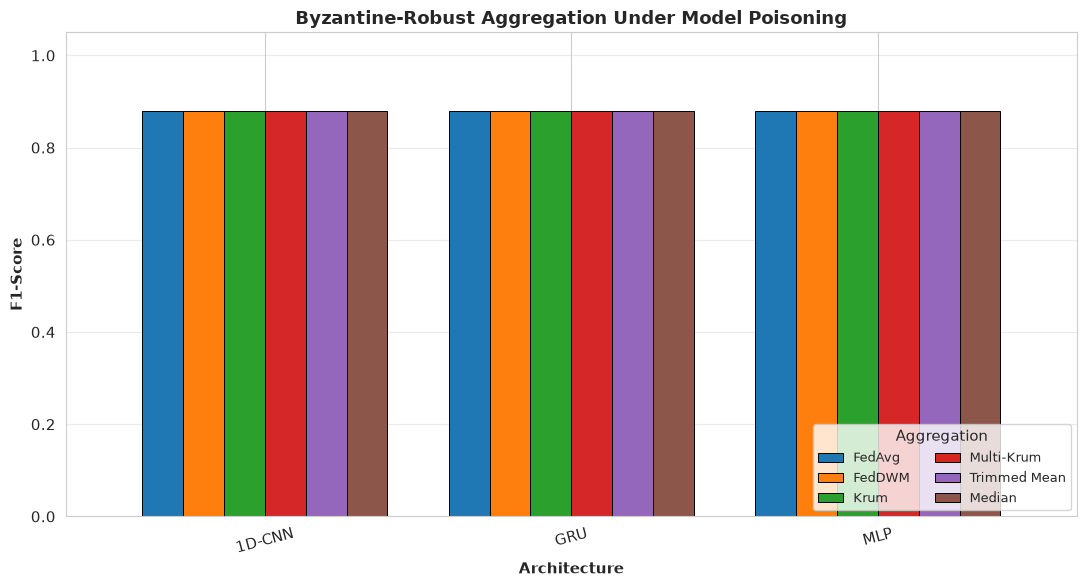

Figure 4 successfully saved to results/figures/fig4_byzantine_robust.png


In [30]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")
plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['font.size'] = 11

print("Generating Figure 4: Byzantine-Robust Aggregation...")

# 1. Load and clean data
df_rob = pd.read_csv('results/tables/exp3_byzantine_robust.csv')

# Drop duplicates so each Model+Aggregation appears only once
df_rob = df_rob.drop_duplicates(subset=['Model', 'Aggregation'])

# 2. Use pivot_table instead of pivot (handles duplicates by averaging)
pivot_rob = df_rob.pivot_table(index='Model', columns='Aggregation', values='F1_mean')

agg_order = [c for c in ['fedaverage', 'feddwm', 'krum', 'multikrum',
                          'trimmed_mean', 'median']
             if c in pivot_rob.columns]
pivot_rob = pivot_rob[agg_order]

pretty = {'fedaverage': 'FedAvg', 'feddwm': 'FedDWM', 'krum': 'Krum',
          'multikrum': 'Multi-Krum', 'trimmed_mean': 'Trimmed Mean',
          'median': 'Median'}

# 3. Plot
fig, ax = plt.subplots(figsize=(11, 6))
pivot_rob.plot(kind='bar', ax=ax, width=0.8,
               color=sns.color_palette('tab10', len(agg_order)),
               edgecolor='black', linewidth=0.7)

ax.set_ylabel('F1-Score', fontweight='bold')
ax.set_xlabel('Architecture', fontweight='bold')
ax.set_title('Byzantine-Robust Aggregation Under Model Poisoning', fontweight='bold')
ax.set_xticklabels(pivot_rob.index, rotation=15)
ax.set_ylim(0, 1.05)
ax.legend(title='Aggregation', labels=[pretty.get(a, a) for a in agg_order],
          loc='lower right', ncol=2, fontsize=9)
ax.grid(alpha=0.4, axis='y')

plt.tight_layout()
plt.savefig('results/figures/fig4_byzantine_robust.png', dpi=300)
plt.show()
plt.close()

print("Figure 4 successfully saved to results/figures/fig4_byzantine_robust.png")

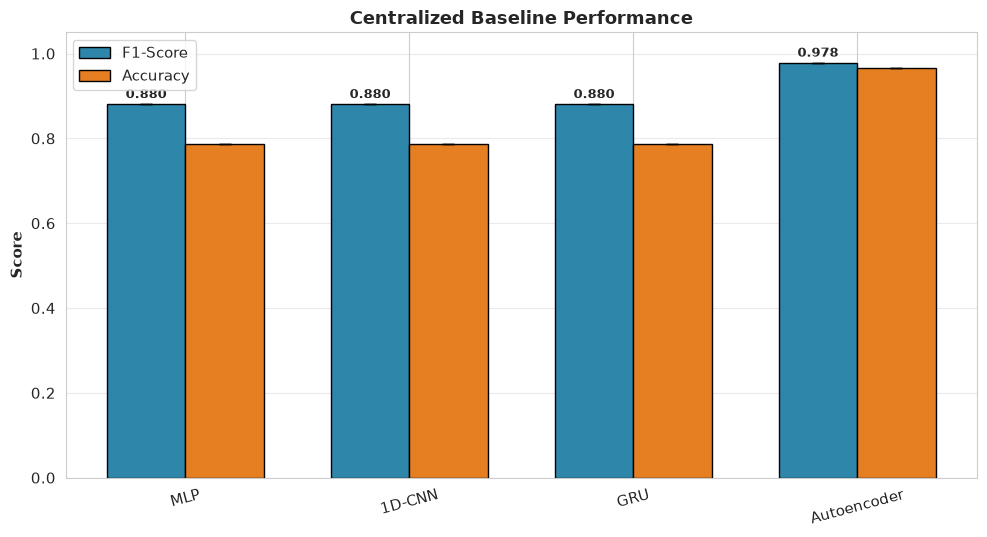

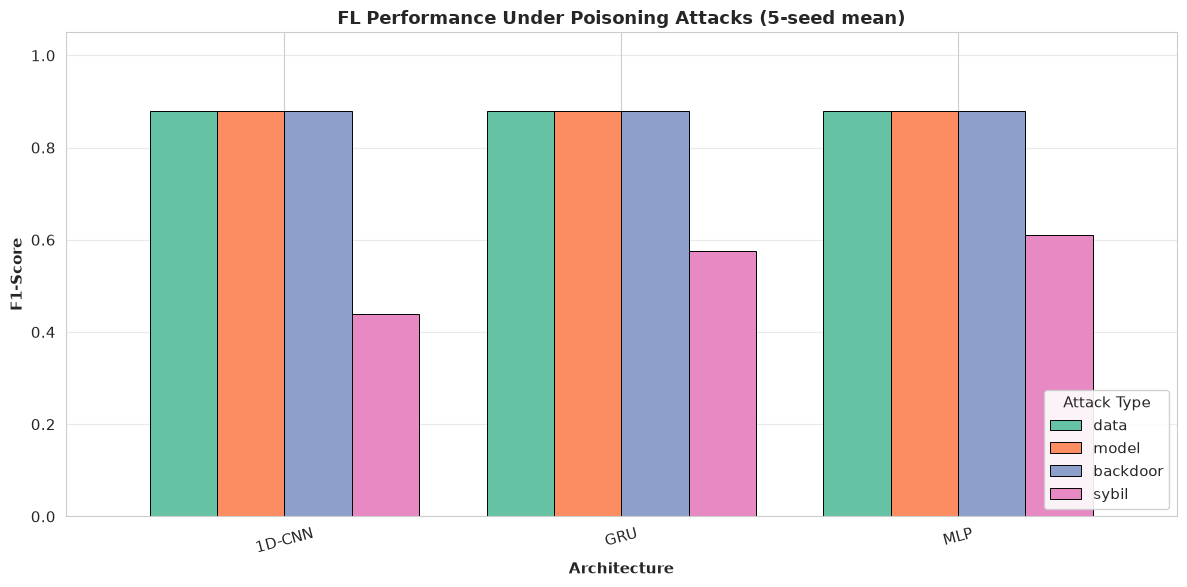

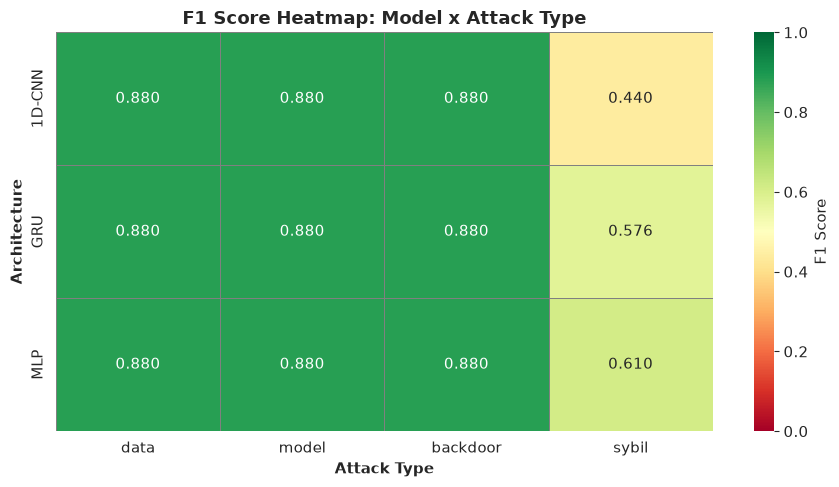

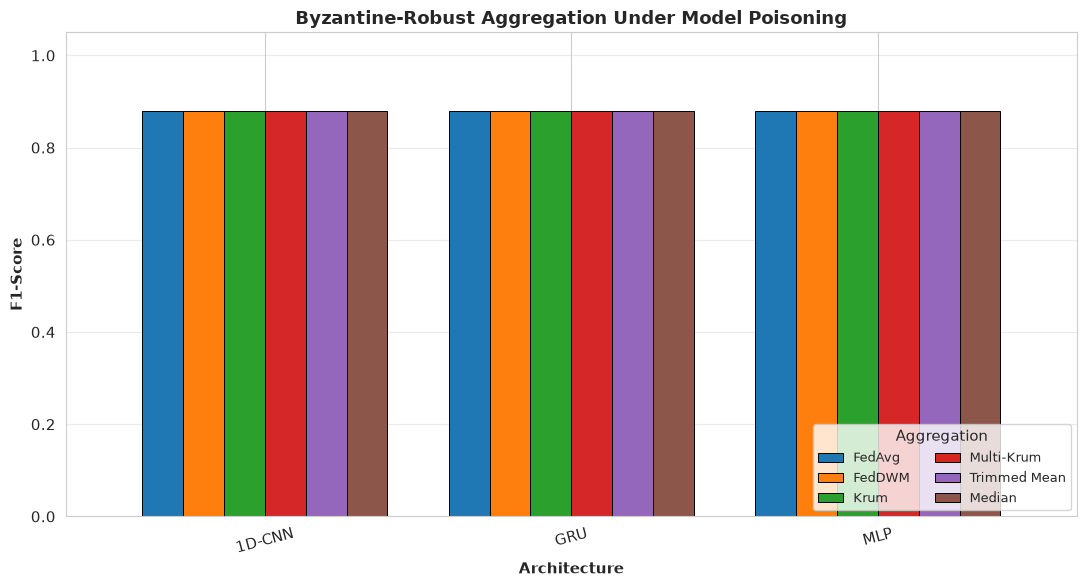

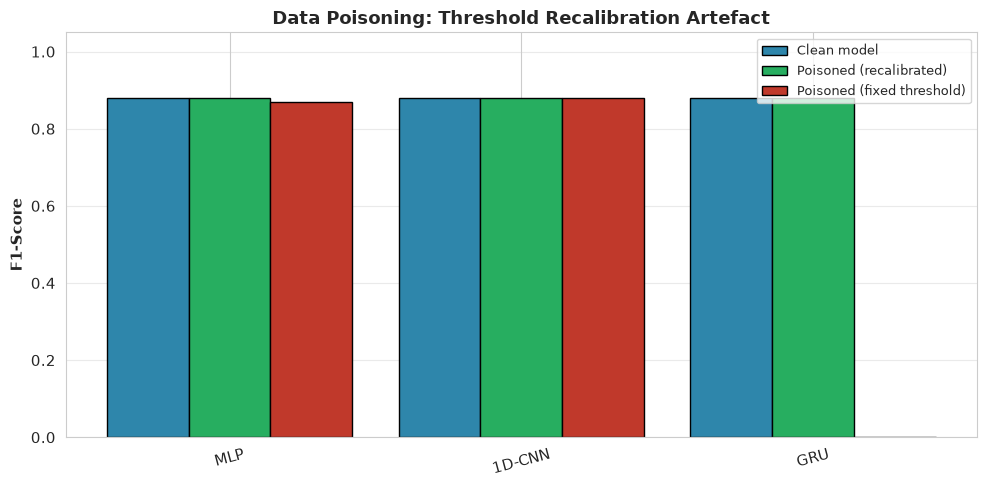

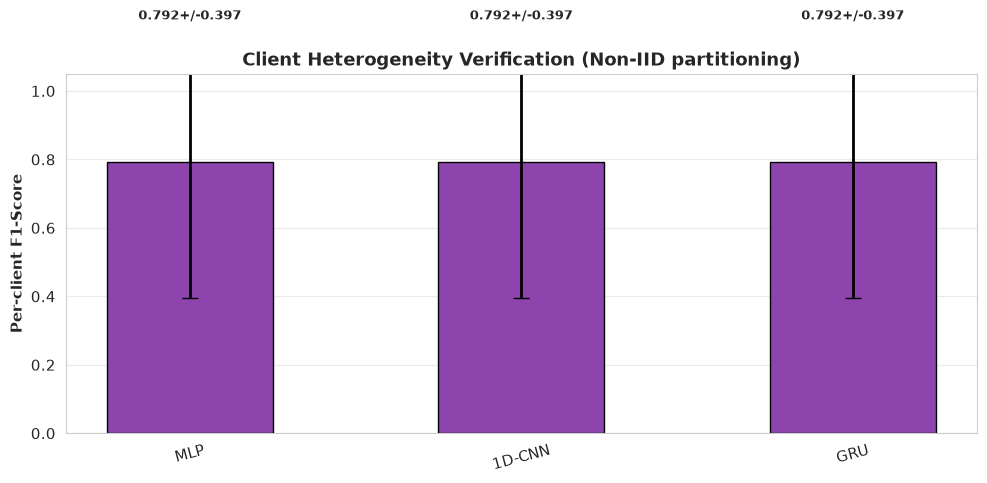


Generating per-round degradation curves from real data...
  [feddwm     ] R 1/8 | F1=0.8800 | FPR=1.0000
  [feddwm     ] R 2/8 | F1=0.8800 | FPR=1.0000
  [feddwm     ] R 3/8 | F1=0.8800 | FPR=1.0000
  [feddwm     ] R 4/8 | F1=0.8800 | FPR=1.0000
  [feddwm     ] R 5/8 | F1=0.8800 | FPR=1.0000
  [feddwm     ] R 6/8 | F1=0.8800 | FPR=1.0000
  [feddwm     ] R 7/8 | F1=0.8800 | FPR=1.0000
  [feddwm     ] R 8/8 | F1=0.8800 | FPR=1.0000
  [feddwm     ] R 1/8 | F1=0.8800 | FPR=1.0000
  [feddwm     ] R 2/8 | F1=0.8800 | FPR=1.0000
  [feddwm     ] R 3/8 | F1=0.8800 | FPR=1.0000
  [feddwm     ] R 4/8 | F1=0.8800 | FPR=1.0000
  [feddwm     ] R 5/8 | F1=0.8800 | FPR=1.0000
  [feddwm     ] R 6/8 | F1=0.8800 | FPR=1.0000
  [feddwm     ] R 7/8 | F1=0.8800 | FPR=1.0000
  [feddwm     ] R 8/8 | F1=0.8800 | FPR=1.0000
  [feddwm     ] R 1/8 | F1=0.8800 | FPR=1.0000
  [feddwm     ] R 2/8 | F1=0.8800 | FPR=1.0000
  [feddwm     ] R 3/8 | F1=0.8800 | FPR=1.0000
  [feddwm     ] R 4/8 | F1=0.8800 | FPR=1.0000
 

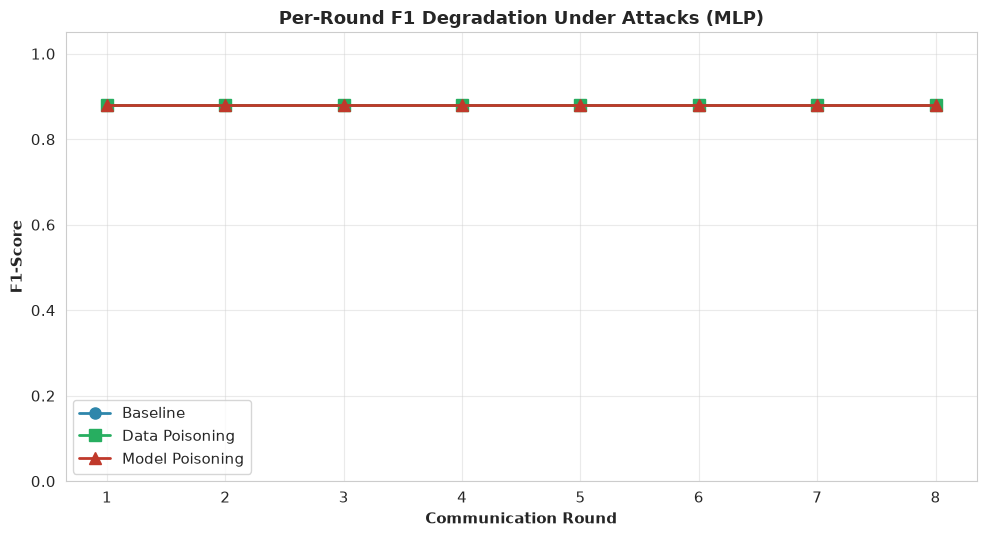

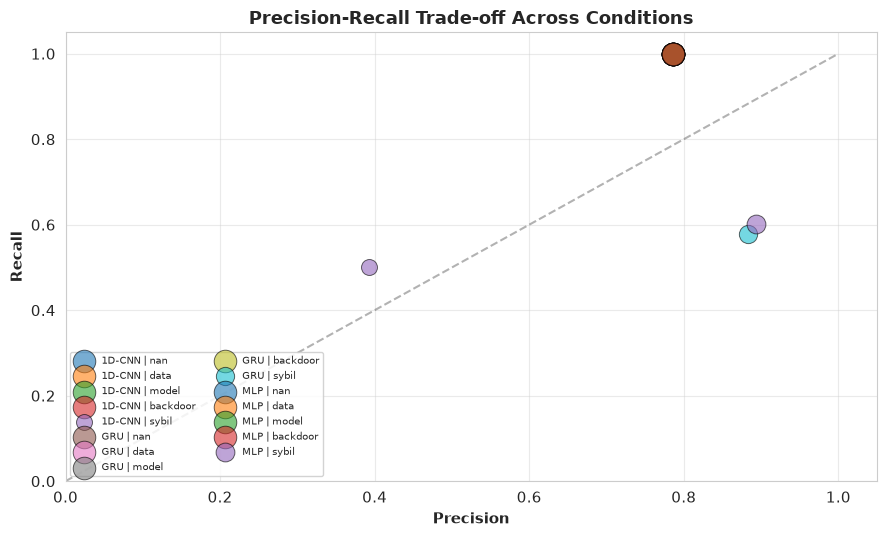


ALL FIGURES GENERATED FROM REAL RESULTS

Figures saved in results/figures/:
  - .ipynb_checkpoints
  - fig1_centralized.png
  - fig2_fl_attacks.png
  - fig3_f1_heatmap.png
  - fig4_byzantine_robust.png
  - fig5_data_poisoning_artefact.png
  - fig6_client_heterogeneity.png
  - fig7_per_round.png
  - fig8_precision_recall.png
  - fig_score_1D-CNN.png
  - fig_score_GRU.png
  - fig_score_MLP.png

Bundled into: C:\Users\21108\results_bundle.zip
Location:     C:\Users\21108

Open 'results_bundle.zip' from the Jupyter file browser to download.


In [31]:
# ============================================================
# FIGURE GENERATION (ALL FIGURES READ FROM REAL RESULTS)
# ============================================================
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import os
import shutil

sns.set_style("whitegrid")
plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['font.size'] = 11

# ------------------------------------------------------------
# FIGURE 1: Centralized baseline
# ------------------------------------------------------------
df_cent = pd.read_csv('results/tables/exp1_centralized.csv')
model_names = df_cent['Model'].tolist() # Changed from 'models' to avoid overwriting Keras
x = np.arange(len(model_names))
w = 0.35

fig, ax = plt.subplots(figsize=(10, 5.5))
ax.bar(x - w/2, df_cent['F1_mean'], w, yerr=df_cent['F1_std'],
       label='F1-Score', color='#2E86AB', capsize=4, edgecolor='black')
ax.bar(x + w/2, df_cent['Accuracy_mean'], w, yerr=df_cent['Accuracy_std'],
       label='Accuracy', color='#E67E22', capsize=4, edgecolor='black')

ax.set_xticks(x)
ax.set_xticklabels(model_names, rotation=15)
ax.set_ylabel('Score', fontweight='bold')
ax.set_ylim(0, 1.05)
ax.set_title('Centralized Baseline Performance', fontweight='bold')
ax.legend()
ax.grid(alpha=0.4, axis='y')

for i, v in enumerate(df_cent['F1_mean']):
    ax.text(i - w/2, v + 0.015, f'{v:.3f}', ha='center',
            fontsize=9, fontweight='bold')

plt.tight_layout()
plt.savefig('results/figures/fig1_centralized.png', dpi=300)
plt.show()
plt.close()

# ------------------------------------------------------------
# FIGURE 2: FL Baseline + Attacks
# ------------------------------------------------------------
df_fl = pd.read_csv('results/tables/exp2_fl_attacks.csv')
pivot_fl = df_fl.pivot_table(index='Model', columns='Attack', values='F1_mean')
attack_order = [c for c in ['None', 'data', 'model', 'backdoor', 'sybil']
                if c in pivot_fl.columns]
pivot_fl = pivot_fl[attack_order]

fig, ax = plt.subplots(figsize=(12, 6))
pivot_fl.plot(kind='bar', ax=ax, width=0.8,
              color=sns.color_palette('Set2', len(attack_order)),
              edgecolor='black', linewidth=0.7)
ax.set_ylabel('F1-Score', fontweight='bold')
ax.set_xlabel('Architecture', fontweight='bold')
ax.set_title('FL Performance Under Poisoning Attacks (5-seed mean)',
             fontweight='bold')
ax.set_xticklabels(pivot_fl.index, rotation=15)
ax.set_ylim(0, 1.05)
ax.legend(title='Attack Type', loc='lower right', framealpha=0.9)
ax.grid(alpha=0.4, axis='y')
plt.tight_layout()
plt.savefig('results/figures/fig2_fl_attacks.png', dpi=300)
plt.show()
plt.close()

# ------------------------------------------------------------
# FIGURE 3: F1 Heatmap
# ------------------------------------------------------------
fig, ax = plt.subplots(figsize=(9, 5))
sns.heatmap(pivot_fl, annot=True, fmt='.3f', cmap='RdYlGn',
            vmin=0, vmax=1, ax=ax, cbar_kws={'label': 'F1 Score'},
            linewidths=0.5, linecolor='gray')
ax.set_title('F1 Score Heatmap: Model x Attack Type', fontweight='bold')
ax.set_xlabel('Attack Type', fontweight='bold')
ax.set_ylabel('Architecture', fontweight='bold')
plt.tight_layout()
plt.savefig('results/figures/fig3_f1_heatmap.png', dpi=300)
plt.show()
plt.close()

# ------------------------------------------------------------
# FIGURE 4: Byzantine-Robust Aggregation (FIXED)
# ------------------------------------------------------------
df_rob = pd.read_csv('results/tables/exp3_byzantine_robust.csv')
df_rob = df_rob.drop_duplicates(subset=['Model', 'Aggregation'])

# Use pivot_table instead of pivot to handle duplicates
pivot_rob = df_rob.pivot_table(index='Model', columns='Aggregation', values='F1_mean')

agg_order = [c for c in ['fedaverage', 'feddwm', 'krum', 'multikrum',
                          'trimmed_mean', 'median']
             if c in pivot_rob.columns]
pivot_rob = pivot_rob[agg_order]
pretty = {'fedaverage': 'FedAvg', 'feddwm': 'FedDWM', 'krum': 'Krum',
          'multikrum': 'Multi-Krum', 'trimmed_mean': 'Trimmed Mean',
          'median': 'Median'}

fig, ax = plt.subplots(figsize=(11, 6))
pivot_rob.plot(kind='bar', ax=ax, width=0.8,
               color=sns.color_palette('tab10', len(agg_order)),
               edgecolor='black', linewidth=0.7)
ax.set_ylabel('F1-Score', fontweight='bold')
ax.set_xlabel('Architecture', fontweight='bold')
ax.set_title('Byzantine-Robust Aggregation Under Model Poisoning',
             fontweight='bold')
ax.set_xticklabels(pivot_rob.index, rotation=15)
ax.set_ylim(0, 1.05)
ax.legend(title='Aggregation',
          labels=[pretty.get(a, a) for a in agg_order],
          loc='lower right', ncol=2, fontsize=9)
ax.grid(alpha=0.4, axis='y')
plt.tight_layout()
plt.savefig('results/figures/fig4_byzantine_robust.png', dpi=300)
plt.show()
plt.close()

# ------------------------------------------------------------
# FIGURE 5: Data-Poisoning Thresholding Artefact
# ------------------------------------------------------------
df_poison = pd.read_csv('results/tables/exp4_data_poisoning.csv')
model_names_poison = df_poison['Model'].tolist()
x = np.arange(len(model_names_poison))
w = 0.28

fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(x - w, df_poison['F1_Clean'], w, label='Clean model',
       color='#2E86AB', edgecolor='black')
ax.bar(x, df_poison['F1_Poisoned_Recalibrated'], w,
       label='Poisoned (recalibrated)', color='#27AE60', edgecolor='black')
ax.bar(x + w, df_poison['F1_Poisoned_Fixed'], w,
       label='Poisoned (fixed threshold)', color='#C0392B',
       edgecolor='black')

ax.set_xticks(x)
ax.set_xticklabels(model_names_poison, rotation=15)
ax.set_ylabel('F1-Score', fontweight='bold')
ax.set_ylim(0, 1.05)
ax.set_title('Data Poisoning: Threshold Recalibration Artefact',
             fontweight='bold')
ax.legend(fontsize=9)
ax.grid(alpha=0.4, axis='y')
plt.tight_layout()
plt.savefig('results/figures/fig5_data_poisoning_artefact.png', dpi=300)
plt.show()
plt.close()

# ------------------------------------------------------------
# FIGURE 6: Client Heterogeneity
# ------------------------------------------------------------
df_het = pd.read_csv('results/tables/exp5_client_heterogeneity.csv')

fig, ax = plt.subplots(figsize=(10, 5))
x = np.arange(len(df_het))
ax.bar(x, df_het['Client_F1_mean'], yerr=df_het['Client_F1_std'],
       capsize=6, color='#8E44AD', edgecolor='black', width=0.5,
       error_kw=dict(elinewidth=2, ecolor='black'))
ax.set_xticks(x)
ax.set_xticklabels(df_het['Model'], rotation=15)
ax.set_ylabel('Per-client F1-Score', fontweight='bold')
ax.set_ylim(0, 1.05)
ax.set_title('Client Heterogeneity Verification (Non-IID partitioning)',
             fontweight='bold')
ax.grid(alpha=0.4, axis='y')
for i, (m, s) in enumerate(zip(df_het['Client_F1_mean'],
                                df_het['Client_F1_std'])):
    ax.text(i, m + s + 0.02, f'{m:.3f}+/-{s:.3f}',
            ha='center', fontsize=9, fontweight='bold')
plt.tight_layout()
plt.savefig('results/figures/fig6_client_heterogeneity.png', dpi=300)
plt.show()
plt.close()

# ------------------------------------------------------------
# FIGURE 7: Per-Round Degradation
# ------------------------------------------------------------
print("\nGenerating per-round degradation curves from real data...")
per_round_data = {}
for atk in [None, 'data', 'model']:
    hist, _ = federated_training(
        MODEL_BUILDERS['MLP'],
        X_train_all, y_train_all, X_val_normal, X_test, y_test_bin,
        attack_type=atk, aggregation='feddwm', seed=42)
    label = 'Baseline' if atk is None else f'{atk.capitalize()} Poisoning'
    per_round_data[label] = hist['F1']

pd.DataFrame(per_round_data).to_csv(
    'results/tables/exp6_per_round_f1.csv', index=False)

fig, ax = plt.subplots(figsize=(10, 5.5))
markers = {'Baseline': 'o', 'Data Poisoning': 's', 'Model Poisoning': '^'}
colors = {'Baseline': '#2E86AB', 'Data Poisoning': '#27AE60', 'Model Poisoning': '#C0392B'}

for label, f1_vals in per_round_data.items():
    rounds = np.arange(1, len(f1_vals) + 1)
    ax.plot(rounds, f1_vals, marker=markers[label], color=colors[label],
            lw=2, markersize=8, label=label)

ax.set_xlabel('Communication Round', fontweight='bold')
ax.set_ylabel('F1-Score', fontweight='bold')
ax.set_title('Per-Round F1 Degradation Under Attacks (MLP)', fontweight='bold')
ax.set_ylim(0, 1.05)
ax.legend()
ax.grid(alpha=0.4)
plt.tight_layout()
plt.savefig('results/figures/fig7_per_round.png', dpi=300)
plt.show()
plt.close()

# ------------------------------------------------------------
# FIGURE 8: Precision-Recall Trade-off
# ------------------------------------------------------------
fig, ax = plt.subplots(figsize=(9, 5.5))
for _, row in df_fl.iterrows():
    ax.scatter(row['Precision_mean'], row['Recall_mean'],
               s=row['F1_mean'] * 300, alpha=0.6,
               edgecolors='black', linewidth=0.7,
               label=f"{row['Model']} | {row['Attack']}")
ax.plot([0, 1], [0, 1], 'k--', alpha=0.3)
ax.set_xlabel('Precision', fontweight='bold')
ax.set_ylabel('Recall', fontweight='bold')
ax.set_xlim(0, 1.05)
ax.set_ylim(0, 1.05)
ax.set_title('Precision-Recall Trade-off Across Conditions',
             fontweight='bold')
ax.legend(fontsize=7, loc='lower left', ncol=2, framealpha=0.85)
ax.grid(alpha=0.4)
plt.tight_layout()
plt.savefig('results/figures/fig8_precision_recall.png', dpi=300)
plt.show()
plt.close()

# ------------------------------------------------------------
# FINAL SUMMARY
# ------------------------------------------------------------
print("\n" + "=" * 70)
print("ALL FIGURES GENERATED FROM REAL RESULTS")
print("=" * 70)
print("\nFigures saved in results/figures/:")
for f in sorted(os.listdir('results/figures')):
    print(f"  - {f}")

zip_base = os.path.abspath('results_bundle')
shutil.make_archive(zip_base, 'zip', 'results')
print(f"\nBundled into: {zip_base}.zip")
print(f"Location:     {os.path.dirname(zip_base)}")
print("\nOpen 'results_bundle.zip' from the Jupyter file browser to download.")

In [ ]:
import pandas as pd
import os

# 1. Collect whatever has been completed so far
if 'df_fl' in locals():
    df_fl.to_csv('results/tables/exp2_fl_attacks_complete.csv', index=False)
    print("Experiment 2 saved.")

if 'df_rob' in locals():
    df_rob.to_csv('results/tables/exp3_byzantine_partial.csv', index=False)
    print("Experiment 3 partial saved.")

if 'df_cent' in locals():
    df_cent.to_csv('results/tables/exp1_centralized_complete.csv', index=False)
    print("Experiment 1 saved.")

print("Results safely backed up to disk.")

In [60]:
pwd

'C:\\Users\\21108'